Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8024 - loss: 0.8954 - val_accuracy: 0.9104 - val_loss: 0.3629
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9158 - loss: 0.3090 - val_accuracy: 0.9310 - val_loss: 0.2492
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9346 - loss: 0.2310 - val_accuracy: 0.9423 - val_loss: 0.2069
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9460 - loss: 0.1878 - val_accuracy: 0.9517 - val_loss: 0.1740
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9545 - loss: 0.1565 - val_accuracy: 0.9570 - val_loss: 0.1526
sigmoid Accuracy: 95.52000164985657
Training Time: 26.967752695083618
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8920 - loss: 0.3809 - val_accuracy: 0.9367 - val_loss: 0.2201
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9453 - loss: 0.1887 - val_accuracy: 0.9549 - val_loss: 0.1625
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━

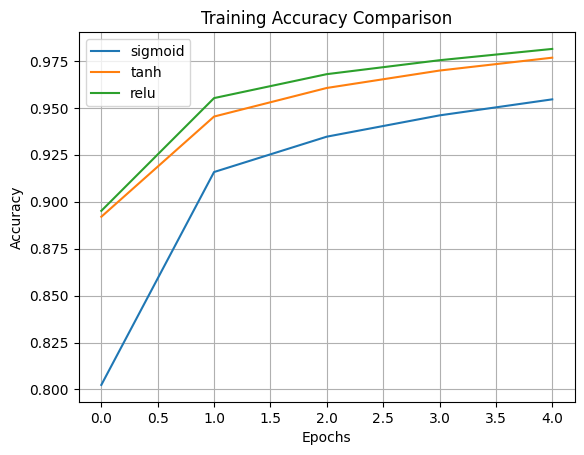

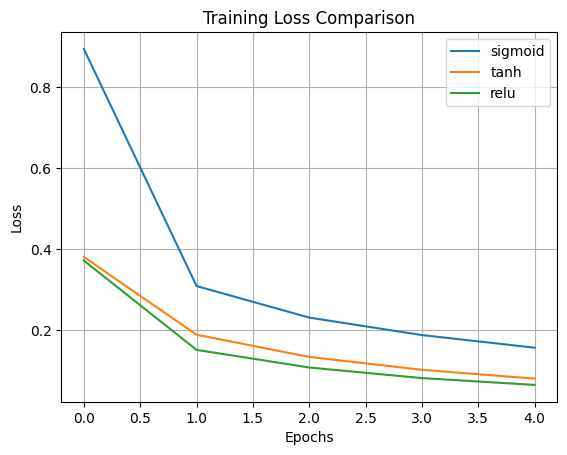

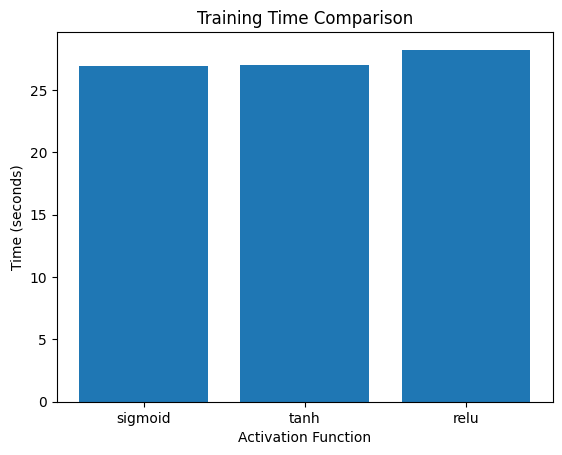

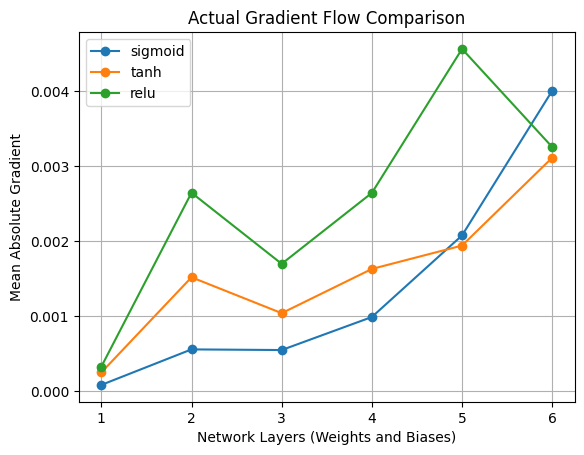


FINAL COMPARISON

Activation: sigmoid
Accuracy: 95.52000164985657 %
Training Time: 26.967752695083618 seconds
Gradient Values: [np.float32(8.36822e-05), np.float32(0.0005578251), np.float32(0.0005492271), np.float32(0.0009900089), np.float32(0.0020790335), np.float32(0.0040100203)]

Activation: tanh
Accuracy: 96.56999707221985 %
Training Time: 26.99683117866516 seconds
Gradient Values: [np.float32(0.0002496566), np.float32(0.0015201061), np.float32(0.001041186), np.float32(0.0016313146), np.float32(0.0019436677), np.float32(0.0031166135)]

Activation: relu
Accuracy: 97.2599983215332 %
Training Time: 28.24015522003174 seconds
Gradient Values: [np.float32(0.00032721923), np.float32(0.0026484432), np.float32(0.0016996475), np.float32(0.0026462774), np.float32(0.004567773), np.float32(0.0032578825)]


In [2]:
# Step 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

# Step 2: Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0

# Step 3: Define activation functions
activations = ['sigmoid', 'tanh', 'relu']
results = {}

# Step 4: Train MLP using different activation functions
for act in activations:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=act),
        tf.keras.layers.Dense(64, activation=act),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    start = time.time()

    history = model.fit(x_train, y_train,
                        epochs=5,
                        batch_size=128,
                        validation_split=0.2,
                        verbose=1)

    training_time = time.time() - start

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results[act] = {
        'model': model,
        'history': history.history,
        'time': training_time,
        'accuracy': accuracy
    }

    print(act, "Accuracy:", accuracy * 100)
    print("Training Time:", training_time)


# Step 5: Plot Training Accuracy
for act in activations:
    plt.plot(results[act]['history']['accuracy'], label=act)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Step 6: Plot Training Loss
for act in activations:
    plt.plot(results[act]['history']['loss'], label=act)

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# Step 7: Plot Training Time
plt.bar(activations, [results[a]['time'] for a in activations])
plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()


# Step 8: Calculate Actual Gradient Flow
x = tf.convert_to_tensor(x_train[:128], dtype=tf.float32)
y = tf.convert_to_tensor(y_train[:128], dtype=tf.int64)

gradient_values = {}

for act in activations:

    model = results[act]['model']

    with tf.GradientTape() as tape:
        predictions = model(x, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y, predictions
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)

    gradient_values[act] = [
        tf.reduce_mean(tf.abs(g)).numpy()
        for g in gradients if g is not None
    ]


# Step 9: Plot Gradient Flow Comparison
for act in activations:
    plt.plot(range(1, len(gradient_values[act]) + 1),
             gradient_values[act],
             marker='o', label=act)

plt.title("Actual Gradient Flow Comparison")
plt.xlabel("Network Layers (Weights and Biases)")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.grid()
plt.show()


# Step 10: Display Final Results
print("\nFINAL COMPARISON")

for act in activations:
    print("\nActivation:", act)
    print("Accuracy:", results[act]['accuracy'] * 100, "%")
    print("Training Time:", results[act]['time'], "seconds")
    print("Gradient Values:", gradient_values[act])

Training Data: (60000, 784)
Testing Data: (10000, 784)
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.7950 - loss: 0.9072 - val_accuracy: 0.9090 - val_loss: 0.3651
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9160 - loss: 0.3107 - val_accuracy: 0.9314 - val_loss: 0.2474
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9345 - loss: 0.2304 - val_accuracy: 0.9431 - val_loss: 0.2007
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9462 - loss: 0.1870 - val_accuracy: 0.9514 - val_loss: 0.1714
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9551 - loss: 0.1565 - val_accuracy: 0.9570 - val_loss: 0.1506
sigmoid Accuracy: 95.69000005722046
Training Time: 38.37824082374573
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.8940 - loss: 0.3815 - val_accuracy: 0.9422 - val_loss: 0.2081
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9451 - loss: 0.1878 - val_accuracy: 0.95

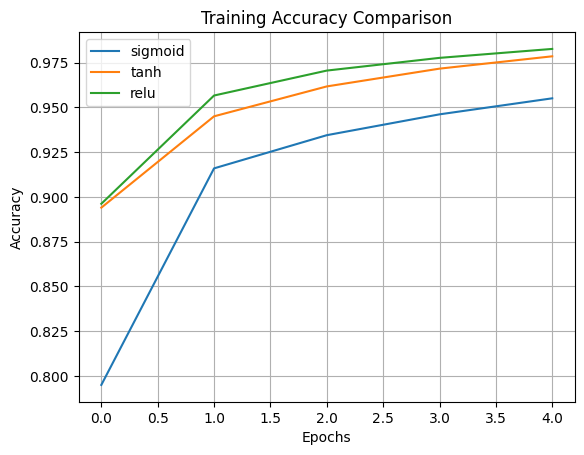

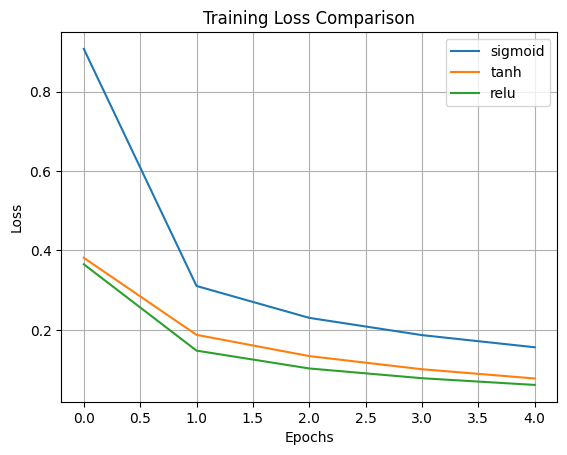

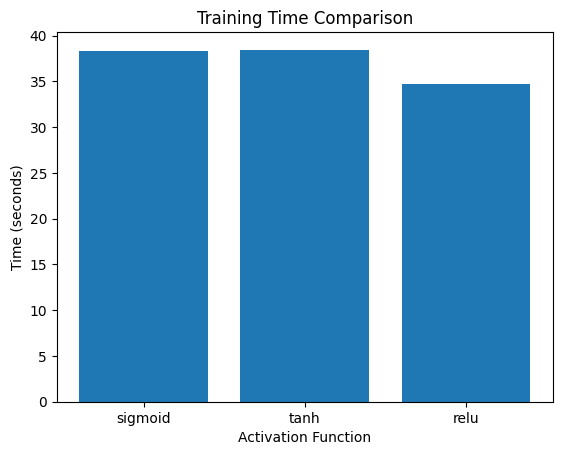

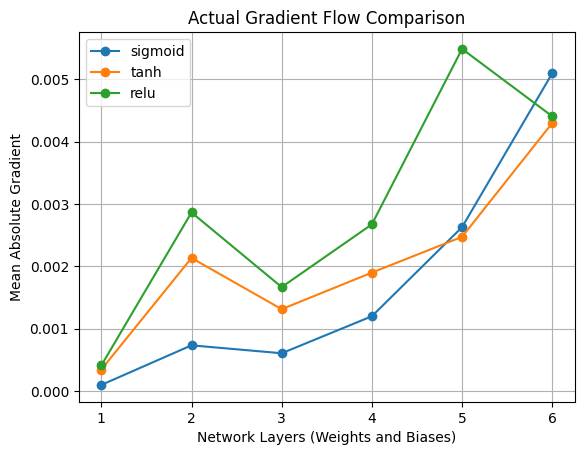


FINAL COMPARISON

Activation: sigmoid
Accuracy: 95.69000005722046 %
Training Time: 38.37824082374573 seconds
Gradient Values: [np.float32(9.870018e-05), np.float32(0.00073369895), np.float32(0.00060660834), np.float32(0.0012001775), np.float32(0.0026290326), np.float32(0.005097075)]

Activation: tanh
Accuracy: 96.96000218391418 %
Training Time: 38.46632933616638 seconds
Gradient Values: [np.float32(0.00034604623), np.float32(0.0021352214), np.float32(0.0013138603), np.float32(0.0019005312), np.float32(0.0024742528), np.float32(0.0042994306)]

Activation: relu
Accuracy: 97.2000002861023 %
Training Time: 34.716930866241455 seconds
Gradient Values: [np.float32(0.0004108525), np.float32(0.0028652924), np.float32(0.001668059), np.float32(0.002674525), np.float32(0.005488758), np.float32(0.004407686)]


In [6]:
# Step 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import struct

# Step 2: Load Local MNIST Dataset

def load_images(file):
    with open(file, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
    return images.reshape(num, rows * cols)

def load_labels(file):
    with open(file, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

x_train = load_images('MNIST/train-images-idx3-ubyte').astype('float32') / 255.0
y_train = load_labels('MNIST/train-labels-idx1-ubyte')

x_test = load_images('MNIST/t10k-images-idx3-ubyte').astype('float32') / 255.0
y_test = load_labels('MNIST/t10k-labels-idx1-ubyte')

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# Step 3: Define Activation Functions
activations = ['sigmoid', 'tanh', 'relu']
results = {}

# Step 4: Train MLP using different activation functions
for act in activations:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=act),
        tf.keras.layers.Dense(64, activation=act),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    start = time.time()

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=1
    )

    training_time = time.time() - start

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results[act] = {
        'model': model,
        'history': history.history,
        'time': training_time,
        'accuracy': accuracy
    }

    print(act, "Accuracy:", accuracy * 100)
    print("Training Time:", training_time)

# Step 5: Plot Training Accuracy
for act in activations:
    plt.plot(results[act]['history']['accuracy'], label=act)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Step 6: Plot Training Loss
for act in activations:
    plt.plot(results[act]['history']['loss'], label=act)

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Step 7: Plot Training Time
plt.bar(activations, [results[a]['time'] for a in activations])
plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()

# Step 8: Calculate Actual Gradient Flow
x = tf.convert_to_tensor(x_train[:128], dtype=tf.float32)
y = tf.convert_to_tensor(y_train[:128], dtype=tf.int64)

gradient_values = {}

for act in activations:

    model = results[act]['model']

    with tf.GradientTape() as tape:
        predictions = model(x, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y, predictions
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)

    gradient_values[act] = [
        tf.reduce_mean(tf.abs(g)).numpy()
        for g in gradients if g is not None
    ]

# Step 9: Plot Gradient Flow Comparison
for act in activations:
    plt.plot(
        range(1, len(gradient_values[act]) + 1),
        gradient_values[act],
        marker='o',
        label=act
    )

plt.title("Actual Gradient Flow Comparison")
plt.xlabel("Network Layers (Weights and Biases)")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.grid()
plt.show()

# Step 10: Display Final Results
print("\nFINAL COMPARISON")

for act in activations:
    print("\nActivation:", act)
    print("Accuracy:", results[act]['accuracy'] * 100, "%")
    print("Training Time:", results[act]['time'], "seconds")
    print("Gradient Values:", gradient_values[act])

Training Data: (60000, 784)
Testing Data: (10000, 784)
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7852 - loss: 0.9208 - val_accuracy: 0.9085 - val_loss: 0.3665
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9152 - loss: 0.3110 - val_accuracy: 0.9301 - val_loss: 0.2487
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9329 - loss: 0.2313 - val_accuracy: 0.9424 - val_loss: 0.2020
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9457 - loss: 0.1876 - val_accuracy: 0.9503 - val_loss: 0.1726
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9549 - loss: 0.1566 - val_accuracy: 0.9563 - val_loss: 0.1517
sigmoid Accuracy: 95.60999870300293
Training Time: 23.602144241333008
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8933 - loss: 0.3875 - val_accuracy: 0.9410 - val_loss: 0.2111
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9454 - loss: 0.1868 - val_accuracy: 0.9564 - v

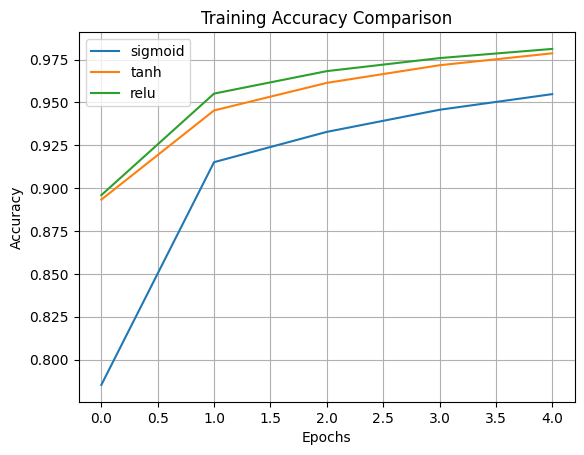

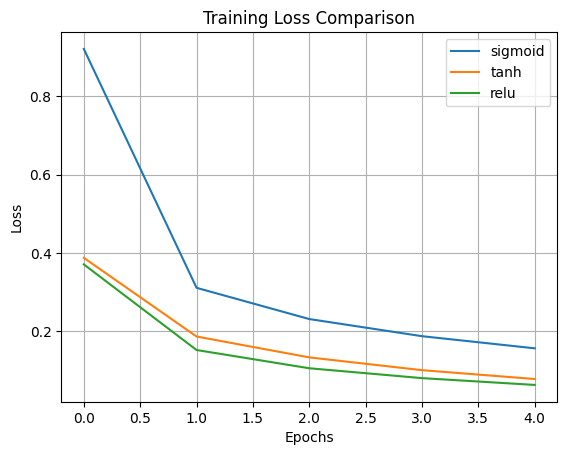

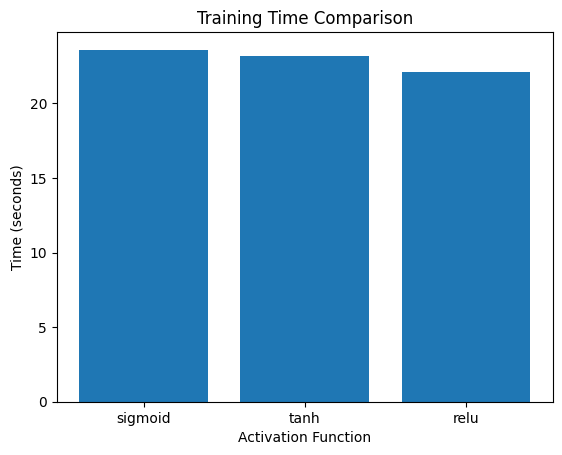

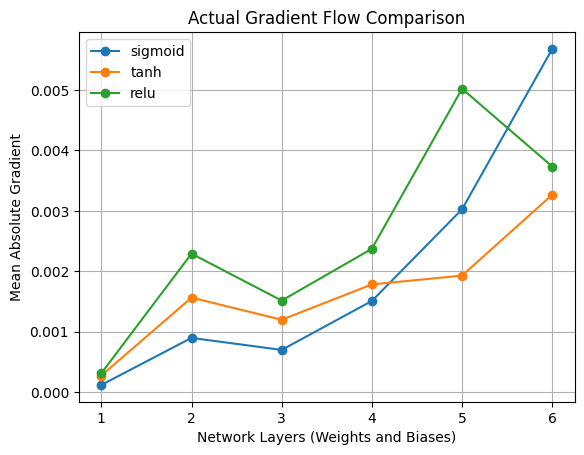


FINAL COMPARISON

Activation: sigmoid
Accuracy: 95.60999870300293 %
Training Time: 23.602144241333008 seconds
Gradient Values: [np.float32(0.00011821175), np.float32(0.00089650386), np.float32(0.00069750415), np.float32(0.001507849), np.float32(0.0030247166), np.float32(0.0056789652)]

Activation: tanh
Accuracy: 97.13000059127808 %
Training Time: 23.206597566604614 seconds
Gradient Values: [np.float32(0.00027372502), np.float32(0.0015625446), np.float32(0.0011966823), np.float32(0.0017814846), np.float32(0.0019272948), np.float32(0.0032656237)]

Activation: relu
Accuracy: 97.39999771118164 %
Training Time: 22.125126123428345 seconds
Gradient Values: [np.float32(0.00031070475), np.float32(0.0022902796), np.float32(0.0015142368), np.float32(0.0023711957), np.float32(0.0050202142), np.float32(0.0037320561)]


In [4]:
# Step 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

# Step 2: Load Local MNIST NPZ Dataset
data = np.load("mnist.npz")

x_train = data["x_train"].reshape(-1, 784).astype("float32") / 255.0
y_train = data["y_train"]

x_test = data["x_test"].reshape(-1, 784).astype("float32") / 255.0
y_test = data["y_test"]

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# Step 3: Define Activation Functions
activations = ['sigmoid', 'tanh', 'relu']
results = {}

# Step 4: Train MLP using different activation functions
for act in activations:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=act),
        tf.keras.layers.Dense(64, activation=act),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    start = time.time()

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=1
    )

    training_time = time.time() - start

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results[act] = {
        'model': model,
        'history': history.history,
        'time': training_time,
        'accuracy': accuracy
    }

    print(act, "Accuracy:", accuracy * 100)
    print("Training Time:", training_time)


# Step 5: Plot Training Accuracy
for act in activations:
    plt.plot(results[act]['history']['accuracy'], label=act)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Step 6: Plot Training Loss
for act in activations:
    plt.plot(results[act]['history']['loss'], label=act)

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# Step 7: Plot Training Time
plt.bar(activations, [results[a]['time'] for a in activations])
plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()


# Step 8: Calculate Actual Gradient Flow
x = tf.convert_to_tensor(x_train[:128], dtype=tf.float32)
y = tf.convert_to_tensor(y_train[:128], dtype=tf.int64)

gradient_values = {}

for act in activations:

    model = results[act]['model']

    with tf.GradientTape() as tape:
        predictions = model(x, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y, predictions
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)

    gradient_values[act] = [
        tf.reduce_mean(tf.abs(g)).numpy()
        for g in gradients if g is not None
    ]


# Step 9: Plot Gradient Flow Comparison
for act in activations:
    plt.plot(
        range(1, len(gradient_values[act]) + 1),
        gradient_values[act],
        marker='o',
        label=act
    )

plt.title("Actual Gradient Flow Comparison")
plt.xlabel("Network Layers (Weights and Biases)")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.grid()
plt.show()


# Step 10: Display Final Results
print("\nFINAL COMPARISON")

for act in activations:
    print("\nActivation:", act)
    print("Accuracy:", results[act]['accuracy'] * 100, "%")
    print("Training Time:", results[act]['time'], "seconds")
    print("Gradient Values:", gradient_values[act])